# COMP9444 Project 003 — Movie knowledge-graph question answering

**Single-notebook integration draft for group review.** This combines Archer's MetaQA EDA with an independently rerunnable evaluation of the team's **locally repaired** baseline. It is not yet the group's submitted notebook or evidence that the original online Christine baseline ran unchanged.

Run all cells in order after setting `METAQA_ROOT` to the local MetaQA folder and `COMP9444_REPO_ROOT` to the local repaired `comp9444-group` checkout. Data are outside Git. The run requires Python 3.13+, Matplotlib, NumPy and scikit-learn; the baseline implementation is imported from the checkout. Saved outputs below are from the local repaired vanilla experiment.

## 1. Introduction and problem statement

MetaQA asks factual questions about movies using a knowledge graph. The task here is to map a question, including its marked entity and relation pattern, to **all** correct answer entities. We will evaluate the answer set on held-out questions, with 1-, 2- and 3-hop subsets reported separately. This notebook first describes the data and then reserves the model and evaluation sections for the group's measured work.

## 2. Data source and experimental scope

- Source: [MetaQA repository](https://github.com/yuyuz/MetaQA), text **vanilla** QA splits, `kb.txt`, and matching question-type files. The downloaded dataset carries a CC BY 3.0 `LICENSE.txt`; retain the dataset citation and the local `SOURCE-MANIFEST.md` with URLs and SHA-256 hashes.
- Each QA line is `question<TAB>answer_1|answer_2|…`; the question entity appears in square brackets. Each KB line is `subject|relation|object`. Question-type lines correspond in order to their QA split.
- This EDA covers nine vanilla QA files (three hops × train/dev/test). It does **not** cover NTM or audio. The model must use the same variant, or the EDA must be extended before comparing results.
- `METAQA_ROOT` must contain `kb.txt` and `1-hop/`, `2-hop/`, `3-hop/`. `data/MetaQA` is the fallback path. The team repository ignores `MetaQA/` and currently does not ship data or an environment specification.

In [1]:
from collections import Counter
from math import ceil
from pathlib import Path
import os
import re

root_setting = os.environ.get("METAQA_ROOT", "data/MetaQA")
DATA_ROOT = Path(root_setting).expanduser().resolve()
print("MetaQA data root:", DATA_ROOT)
print("Set METAQA_ROOT before running if the data is elsewhere.")

### 2.1 Check required files

List the nine QA inputs and KB. This is a source inventory, not a model result.

In [2]:
SPLITS = ("train", "dev", "test")
HOPS = (1, 2, 3)
qa_paths = {
    (hop, split): DATA_ROOT / f"{hop}-hop" / "vanilla" / f"qa_{split}.txt"
    for hop in HOPS for split in SPLITS
}
kb_path = DATA_ROOT / "kb.txt"
missing = [str(p) for p in [kb_path, *qa_paths.values()] if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "MetaQA source files are missing. Set METAQA_ROOT to the folder containing "
        "kb.txt and 1-hop/2-hop/3-hop/vanilla. Missing:\n" + "\n".join(missing)
    )
print("Required files found:", 1 + len(qa_paths))
print("kb.txt", f"{kb_path.stat().st_size:,} bytes")
for hop in HOPS:
    for split in SPLITS:
        p = qa_paths[(hop, split)]
        print(f"{hop}-hop {split:<5} {p.stat().st_size:>12,} bytes  {p.relative_to(DATA_ROOT)}")

Required files found: 10
kb.txt 5,220,771 bytes
1-hop train    6,496,601 bytes  1-hop\vanilla\qa_train.txt
1-hop dev        673,670 bytes  1-hop\vanilla\qa_dev.txt
1-hop test       675,227 bytes  1-hop\vanilla\qa_test.txt
2-hop train   17,250,659 bytes  2-hop\vanilla\qa_train.txt
2-hop dev      2,183,998 bytes  2-hop\vanilla\qa_dev.txt
2-hop test     2,150,912 bytes  2-hop\vanilla\qa_test.txt
3-hop train   26,427,148 bytes  3-hop\vanilla\qa_train.txt
3-hop dev      3,274,801 bytes  3-hop\vanilla\qa_dev.txt
3-hop test     3,328,337 bytes  3-hop\vanilla\qa_test.txt


## 3. Exploratory data analysis

### 3.1 Knowledge graph size and format

Count triples, entity strings, relation labels and malformed rows in the movie KB.

In [3]:
def inspect_kb(path, max_examples=3):
    relations = Counter()
    subjects = set()
    objects = set()
    bad_rows = []
    bad_total = 0
    total = 0
    for line_no, raw in enumerate(path.open(encoding="utf-8-sig"), start=1):
        parts = raw.rstrip("\r\n").split("|")
        if len(parts) != 3 or any(not part.strip() for part in parts):
            bad_total += 1
            if len(bad_rows) < max_examples:
                bad_rows.append((line_no, raw.rstrip("\r\n")[:160]))
            continue
        subject, relation, obj = (part.strip() for part in parts)
        total += 1
        relations[relation] += 1
        subjects.add(subject)
        objects.add(obj)
    return {
        "triples": total,
        "distinct_subjects": len(subjects),
        "distinct_objects": len(objects),
        "distinct_entities_union": len(subjects | objects),
        "relation_counts": relations,
        "malformed_examples": bad_rows,
        "malformed_rows": bad_total,
    }

kb = inspect_kb(kb_path)
print("Valid triples:", f"{kb['triples']:,}")
print("Distinct entities (subject ∪ object):", f"{kb['distinct_entities_union']:,}")
print("Relations:", len(kb["relation_counts"]))
print("Most common relations:", kb["relation_counts"].most_common(10))
print("Malformed KB examples (up to three):", kb["malformed_examples"])
print("Malformed KB rows:", kb["malformed_rows"])

Valid triples: 134,741
Distinct entities (subject ∪ object): 43,234
Relations: 9
Most common relations: [('starred_actors', 33735), ('has_tags', 28944), ('written_by', 19543), ('release_year', 16726), ('directed_by', 15966), ('has_genre', 15895), ('in_language', 3482), ('has_imdb_rating', 328), ('has_imdb_votes', 122)]
Malformed KB examples (up to three): []
Malformed KB rows: 0


### 3.2 QA size, answer multiplicity and question length

Count valid rows, bracketed entities, multiple-answer questions, 50th/90th percentile word length, duplicate question wording within each split, and malformed rows. Here a "word" is a whitespace-separated token; it is not a tokenizer output.

In [4]:
ENTITY_MARKER = re.compile(r"\[[^\[\]]+\]")

def nearest_rank(sorted_values, percent):
    if not sorted_values:
        return None
    return sorted_values[ceil(len(sorted_values) * percent / 100) - 1]

def inspect_qa(path, max_examples=2):
    answer_multiplicity = Counter()
    word_lengths = []
    questions = set()
    examples = []
    bad_examples = []
    rows = bracketed = repeated_questions = bad_total = 0
    for line_no, raw in enumerate(path.open(encoding="utf-8-sig"), start=1):
        line = raw.rstrip("\r\n")
        if line.count("\t") != 1:
            bad_total += 1
            if len(bad_examples) < max_examples:
                bad_examples.append((line_no, line[:160]))
            continue
        question, answer_text = line.split("\t", 1)
        answers = [a.strip() for a in answer_text.split("|")]
        if not question.strip() or not answers or any(not a for a in answers):
            bad_total += 1
            if len(bad_examples) < max_examples:
                bad_examples.append((line_no, line[:160]))
            continue
        rows += 1
        bracketed += bool(ENTITY_MARKER.search(question))
        answer_multiplicity[len(answers)] += 1
        word_lengths.append(len(question.split()))
        key = question.strip().casefold()
        repeated_questions += key in questions
        questions.add(key)
        if len(examples) < max_examples:
            examples.append((question, answers[:4], len(answers)))
    word_lengths.sort()
    return {
        "rows": rows,
        "bracketed": bracketed,
        "multi_answer": sum(n for k, n in answer_multiplicity.items() if k > 1),
        "max_answers": max(answer_multiplicity, default=0),
        "p50_words": nearest_rank(word_lengths, 50),
        "p90_words": nearest_rank(word_lengths, 90),
        "repeated_questions": repeated_questions,
        "questions": questions,
        "examples": examples,
        "malformed_examples": bad_examples,
        "malformed_rows": bad_total,
    }

qa = {(hop, split): inspect_qa(qa_paths[(hop, split)]) for hop in HOPS for split in SPLITS}
print("hop | split | valid rows | bracketed % | multi-answer % | max answers | p50 / p90 words | repeated exact questions | malformed rows")
for hop in HOPS:
    for split in SPLITS:
        r = qa[(hop, split)]
        pct = lambda n: 100 * n / r["rows"] if r["rows"] else 0
        print(f"{hop:>3} | {split:<5} | {r['rows']:>10,} | {pct(r['bracketed']):>10.1f} | "
              f"{pct(r['multi_answer']):>14.1f} | {r['max_answers']:>11} | "
              f"{str(r['p50_words'])+'/'+str(r['p90_words']):>15} | "
              f"{r['repeated_questions']:>24,} | {r['malformed_rows']:>14,}")

hop | split | valid rows | bracketed % | multi-answer % | max answers | p50 / p90 words | repeated exact questions | malformed rows
  1 | train |     96,106 |      100.0 |           32.9 |          94 |            7/10 |                      212 |              0
  1 | dev   |      9,992 |      100.0 |           32.8 |          57 |            7/10 |                        3 |              0
  1 | test  |      9,947 |      100.0 |           33.3 |          44 |            7/10 |                        5 |              0
  2 | train |    118,980 |      100.0 |           60.4 |         218 |           10/12 |                        0 |              0
  2 | dev   |     14,872 |      100.0 |           60.0 |         173 |           10/12 |                        0 |              0
  2 | test  |     14,872 |      100.0 |           60.0 |         151 |           10/12 |                        0 |              0
  3 | train |    114,196 |      100.0 |           83.8 |         285 |           1

### 3.3 Bounded examples

One training question per hop shows the row shape. Only up to four answers are printed.

In [5]:
for hop in HOPS:
    r = qa[(hop, "train")]
    print(f"\n{hop}-hop train — first training row, showing at most four answers each:")
    for question, answers, total_answers in r["examples"][:1]:
        print("Q:", question)
        print("A:", answers, f"({total_answers} total)")
    print("Malformed sample rows:", r["malformed_examples"])


1-hop train — first training row, showing at most four answers each:
Q: what movies are about [ginger rogers]
A: ['Top Hat', 'Kitty Foyle', 'The Barkleys of Broadway'] (3 total)
Malformed sample rows: []

2-hop train — first training row, showing at most four answers each:
Q: which person wrote the films directed by [Yuriy Norshteyn]
A: ['Sergei Kozlov'] (1 total)
Malformed sample rows: []

3-hop train — first training row, showing at most four answers each:
Q: the films that share actors with the film [Dil Chahta Hai] were released in which years
A: ['1997', '1998', '2003', '2001'] (12 total)
Malformed sample rows: []


### 3.4 Repeated wording across official splits

This compares question text after trimming outside spaces and case-folding. It does not compare answer sets and does **not** by itself establish training leakage. Keep the published splits unchanged; investigate overlaps separately when interpreting results.

In [6]:
overlap = {}
for hop in HOPS:
    train = qa[(hop, "train")]["questions"]
    dev = qa[(hop, "dev")]["questions"]
    test = qa[(hop, "test")]["questions"]
    overlap[hop] = {
        "train_dev": len(train & dev),
        "train_test": len(train & test),
        "dev_test": len(dev & test),
    }
    print(f"{hop}-hop unique exact-question overlap:", overlap[hop])

1-hop unique exact-question overlap: {'train_dev': 53, 'train_test': 45, 'dev_test': 4}
2-hop unique exact-question overlap: {'train_dev': 0, 'train_test': 0, 'dev_test': 0}
3-hop unique exact-question overlap: {'train_dev': 1, 'train_test': 0, 'dev_test': 1}


### 3.5 Question-type labels and source alignment

The labels describe relation-path patterns, not answer entities. A row-count match is necessary but does not independently prove row-by-row semantic alignment.

In [7]:
qtype_status = {}
for hop in HOPS:
    for split in SPLITS:
        path = DATA_ROOT / f"{hop}-hop" / f"qa_{split}_qtype.txt"
        if not path.is_file():
            qtype_status[(hop, split)] = "not present"
            continue
        with path.open(encoding="utf-8-sig") as fh:
            counts = Counter(line.rstrip("\r\n") for line in fh)
        n_types = sum(counts.values())
        n_qa = qa[(hop, split)]["rows"]
        status = "aligned" if n_types == n_qa else "REVIEW: row counts differ"
        qtype_status[(hop, split)] = status
        print(f"{hop}-hop {split}: {n_types:,} type lines vs {n_qa:,} valid QA rows — {status}; "
              f"{len(counts)} question types; "
              f"top labels: {counts.most_common(3)}")
print("Absent qtype files:", [f"{h}-hop/{s}" for (h, s), v in qtype_status.items() if v == "not present"])

1-hop train: 96,106 type lines vs 96,106 valid QA rows — aligned; 13 question types; top labels: [('movie_to_year', 13848), ('movie_to_director', 12602), ('movie_to_actor', 11319)]
1-hop dev: 9,992 type lines vs 9,992 valid QA rows — aligned; 13 question types; top labels: [('movie_to_year', 1458), ('movie_to_director', 1331), ('movie_to_actor', 1141)]
1-hop test: 9,947 type lines vs 9,947 valid QA rows — aligned; 11 question types; top labels: [('movie_to_year', 1420), ('movie_to_director', 1301), ('movie_to_genre', 1143)]


2-hop train: 118,980 type lines vs 118,980 valid QA rows — aligned; 21 question types; top labels: [('movie_to_actor_to_movie', 9336), ('movie_to_director_to_movie', 9146), ('writer_to_movie_to_year', 8170)]
2-hop dev: 14,872 type lines vs 14,872 valid QA rows — aligned; 21 question types; top labels: [('movie_to_actor_to_movie', 1193), ('movie_to_director_to_movie', 1185), ('writer_to_movie_to_year', 1036)]
2-hop test: 14,872 type lines vs 14,872 valid QA rows — aligned; 21 question types; top labels: [('movie_to_actor_to_movie', 1180), ('movie_to_director_to_movie', 1081), ('writer_to_movie_to_year', 1020)]


3-hop train: 114,196 type lines vs 114,196 valid QA rows — aligned; 15 question types; top labels: [('movie_to_actor_to_movie_to_year', 9393), ('movie_to_actor_to_movie_to_director', 9323), ('movie_to_actor_to_movie_to_genre', 9235)]
3-hop dev: 14,274 type lines vs 14,274 valid QA rows — aligned; 15 question types; top labels: [('movie_to_actor_to_movie_to_writer', 1172), ('movie_to_actor_to_movie_to_year', 1163), ('movie_to_director_to_movie_to_year', 1155)]
3-hop test: 14,274 type lines vs 14,274 valid QA rows — aligned; 15 question types; top labels: [('movie_to_actor_to_movie_to_writer', 1182), ('movie_to_actor_to_movie_to_director', 1166), ('movie_to_director_to_movie_to_writer', 1151)]
Absent qtype files: []


In [8]:
# Fail before model work if the source data is incomplete or misaligned.
assert kb["malformed_rows"] == 0, "Malformed KB rows need review"
for hop in HOPS:
    for split in SPLITS:
        result = qa[(hop, split)]
        assert result["rows"] > 0, (hop, split, "empty QA split")
        assert result["malformed_rows"] == 0, (hop, split, "malformed QA rows")
        assert qtype_status[(hop, split)] == "aligned", (hop, split, qtype_status[(hop, split)])
print("Source checks passed: KB format, 9 QA splits, 9 matching qtype files.")

Source checks passed: KB format, 9 QA splits, 9 matching qtype files.


### 3.6 Questions by hop and split

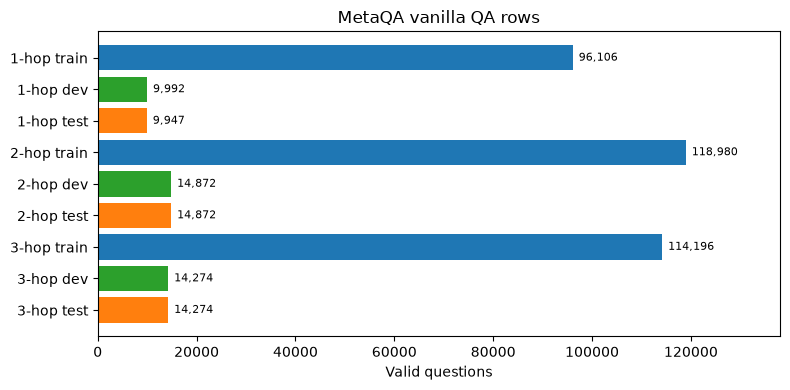

In [9]:
import matplotlib.pyplot as plt

labels = [f"{hop}-hop {split}" for hop in HOPS for split in SPLITS]
counts = [qa[(hop, split)]["rows"] for hop in HOPS for split in SPLITS]
colors = {"train": "tab:blue", "dev": "tab:green", "test": "tab:orange"}
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels, counts, color=[colors[split] for hop in HOPS for split in SPLITS])
ax.invert_yaxis()
ax.set(xlabel="Valid questions", title="MetaQA vanilla QA rows")
for i, count in enumerate(counts):
    ax.text(count + 1200, i, f"{count:,}", va="center", fontsize=8)
ax.set_xlim(0, max(counts) * 1.16)
plt.tight_layout()
plt.show()

### 3.7 Observations from the verified vanilla run

The nine files contain **329,282 train, 39,138 dev and 39,093 test questions** (407,513 total). The KB contains **134,741 triples and nine relation labels**. In the train splits, multiple-answer questions occur in about **32.9% / 60.4% / 83.8%** of 1-/2-/3-hop rows, so single-answer accuracy would be an incomplete metric. The training qtype files have **13 / 21 / 15 distinct labels** by hop. Some exact question strings repeat across splits, mainly at one hop; this observation alone does not classify them as leakage. These values were checked on the source files in the project EDA run; the cells above recompute them on the reader's data.

## 4. Models and methods — local repaired baseline

**Group code source:** [ltangg2/comp9444](https://github.com/ltangg2/comp9444), reviewed at `main` commit `0f5a3fbf745937864b007bd17f95fa6e68e659b9`. The group handoff identifies this as **Christine's baseline**; confirm exact authorship and any borrowed work before submission. Archer's contribution here is the data-loading/EDA draft, not the baseline implementation.

The current interface is `Preprocess().preprocess()`, then `get_graph()` and `get_data(split)` returning `(questions, question_types, answer_lists)`. [`Question_Classifer`](https://github.com/ltangg2/comp9444/blob/main/baseline/baseline_question_classifer.py) normalizes the bracketed entity, fits TF-IDF word 1–2 grams and logistic regression to predict a question type. [`Baseline`](https://github.com/ltangg2/comp9444/blob/main/baseline/baseline.py) converts the predicted type into a relation path, traverses the KB graph and returns an answer set. Its QA metric is exact equality of predicted and gold answer **sets**; question-type classification accuracy is a separate diagnostic.

**Version boundary:** the linked online `main` at `0f5a3fb` cannot run unchanged: `Graph.add_entity` references undefined `u`; preprocessing requires an absent entity dictionary and NTM files. This experiment uses the **uncommitted local pilot checkout** with three targeted repairs: `u → node_u` in `Graph.add_entity`, configurable `data_root` and `folders=("vanilla",)` with the absent entity dictionary treated as optional, and a question/answer length guard in `Baseline.evaluate`. The exact three-file diff accompanies this review draft at `notebooks/baseline-vanilla-local-repair.patch`; apply it to a clean checkout of `0f5a3fb` before rerunning. The Notebook imports that patched checkout; it does not claim the online original ran. If a later experiment uses NTM too, obtain those files and extend the EDA first.

**Environment in this local run:** Python 3.13.2, NumPy 2.5.3, scikit-learn 1.9.1, Matplotlib 3.11.2, nbformat 5.11.1. The data source and its hashes are recorded in `SOURCE-MANIFEST.md` beside the downloaded MetaQA folder. A new machine needs this data folder, the patch and the team baseline code, with `METAQA_ROOT` and `COMP9444_REPO_ROOT` set before execution.

**Protocol:** train once on all 329,282 vanilla train questions, using the classifier's fixed TF-IDF and logistic-regression settings; score each dev hop, then each test hop without further tuning. The classifier accuracy and answer-set exact-match below use separate denominators shown in the output. The KB graph is the same fixed dataset source across splits. The existing `run_baseline.py` learning-curve prefixes alter hop composition; this notebook omits that curve.

In [10]:
from time import perf_counter
import inspect
import subprocess
import sys

repo_setting = os.environ.get("COMP9444_REPO_ROOT")
if not repo_setting:
    raise RuntimeError("Set COMP9444_REPO_ROOT to the local repaired comp9444-group checkout")
REPO_ROOT = Path(repo_setting).expanduser().resolve()
if not (REPO_ROOT / "baseline" / "graph.py").is_file():
    raise FileNotFoundError(f"No baseline package at {REPO_ROOT}")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from baseline.graph import Graph
from baseline.baseline_preprocess import Preprocess
from baseline.baseline_question_classifer import Question_Classifer
from baseline.baseline import Baseline

# Smoke-test all three local repairs before spending time on model training.
probe = Graph()
probe.add_entity(("movie", "__integration_smoke__"), "movie")
assert "data_root" in inspect.signature(Preprocess).parameters
assert "folders" in inspect.signature(Preprocess).parameters
try:
    Baseline(probe, None).evaluate(["one question"], [])
except ValueError:
    pass
else:
    raise AssertionError("Baseline.evaluate must reject mismatched lengths")

head = subprocess.run(
    ["git", "rev-parse", "HEAD"], cwd=REPO_ROOT, text=True,
    capture_output=True, check=True,
).stdout.strip()
print("Local baseline checkout:", REPO_ROOT)
print("Base HEAD:", head)
print("Required local repairs: graph node variable; data-root/vanilla config; length check — smoke passed")

### 4.1 Load vanilla splits through the repaired preprocessor

In [11]:
model_started = perf_counter()
model_preprocess = Preprocess(data_root=DATA_ROOT, folders=("vanilla",))
model_preprocess.preprocess()
train_questions, train_types, train_answers = model_preprocess.get_data("train")
assert len(train_questions) == len(train_types) == len(train_answers)
assert len(train_questions) == sum(qa[(hop, "train")]["rows"] for hop in HOPS)
for split in ("dev", "test"):
    for hop in HOPS:
        n = len(model_preprocess.questions[split][hop]["vanilla"])
        assert n == len(model_preprocess.answers[split][hop]["vanilla"])
        assert n == len(model_preprocess.qs_types[split][hop])
        assert n == qa[(hop, split)]["rows"]
graph = model_preprocess.get_graph()
print(f"Loaded {len(train_questions):,} vanilla training rows and {len(set(train_types))} question-type labels")
print(f"Preprocessing elapsed: {perf_counter() - model_started:.1f}s")

Loaded 329,282 vanilla training rows and 49 question-type labels
Preprocessing elapsed: 4.3s


### 4.2 Fit the question-type classifier on train only

In [12]:
question_classifier = Question_Classifer()
question_classifier.train(train_questions, train_types)
baseline = Baseline(graph, question_classifier)
print(f"Classifier trained on all {len(train_questions):,} vanilla train rows")
print(f"Elapsed since preprocessing began: {perf_counter() - model_started:.1f}s")

Classifier trained on all 329,282 vanilla train rows
Elapsed since preprocessing began: 191.6s


## 5. Results — measured local repaired vanilla experiment

For each held-out hop, report **question-type classification accuracy** and **QA answer-set exact-match** separately. An empty prediction is counted even if the gold answer set is nonempty. The error rate plot below starts at zero. The full evaluation loop follows the local `evaluate_vanilla.py` logic, inlined here so this notebook does not depend on that untracked driver file. These numbers are not from the online original baseline.

In [13]:
ENTITY_PATTERN = re.compile(r"\[([^\]]+)\]")

def evaluate_hop(classifier, model, questions, labels, answers):
    """Return classifier accuracy and QA answer-set exact-match for one hop."""
    if not (len(questions) == len(labels) == len(answers)):
        raise ValueError("Question, type, and answer counts differ")
    features = classifier.vectorizer.transform(
        classifier.normalise_questions(questions)
    )
    predicted_types = classifier.model.predict(features)
    type_correct = qa_correct = empty_predictions = 0
    failure_examples = []
    for question, true_type, true_answers, predicted_type in zip(
        questions, labels, answers, predicted_types, strict=True
    ):
        type_correct += predicted_type == true_type
        relation_path, node_path = model.get_relation_path(predicted_type)
        predicted_answers = model.answer_question(
            ENTITY_PATTERN.findall(question), node_path, relation_path
        )
        correct = predicted_answers == set(true_answers)
        qa_correct += correct
        empty_predictions += not predicted_answers
        if not correct and len(failure_examples) < 5:
            failure_examples.append({
                "question": question,
                "true_type": true_type,
                "predicted_type": predicted_type,
                "true_answers": true_answers[:5],
                "predicted_answers": sorted(predicted_answers)[:5],
            })
    n = len(questions)
    return {
        "n": n,
        "type_correct": int(type_correct),
        "type_accuracy": type_correct / n,
        "qa_correct": int(qa_correct),
        "qa_exact_match": qa_correct / n,
        "empty_predictions": int(empty_predictions),
        "empty_prediction_rate": empty_predictions / n,
        "failure_examples": failure_examples,
    }

evaluation = {}
for split in ("dev", "test"):
    evaluation[split] = {}
    for hop in HOPS:
        questions = model_preprocess.questions[split][hop]["vanilla"]
        labels = model_preprocess.qs_types[split][hop]
        answers = model_preprocess.answers[split][hop]["vanilla"]
        evaluation[split][hop] = evaluate_hop(
            question_classifier, baseline, questions, labels, answers
        )
print("split hop | n | type correct/total (%) | QA exact-set correct/total (%) | empty/total (%)")
for split in ("dev", "test"):
    for hop in HOPS:
        result = evaluation[split][hop]
        n = result["n"]
        print(f"{split:<5} {hop} | {n:,} | "
              f"{result['type_correct']:,}/{n:,} ({result['type_accuracy']:.2%}) | "
              f"{result['qa_correct']:,}/{n:,} ({result['qa_exact_match']:.2%}) | "
              f"{result['empty_predictions']:,}/{n:,} ({result['empty_prediction_rate']:.2%})")
print(f"Total model elapsed: {perf_counter() - model_started:.1f}s")

split hop | n | type correct/total (%) | QA exact-set correct/total (%) | empty/total (%)
dev   1 | 9,992 | 9,992/9,992 (100.00%) | 9,478/9,992 (94.86%) | 0/9,992 (0.00%)
dev   2 | 14,872 | 14,872/14,872 (100.00%) | 14,328/14,872 (96.34%) | 0/14,872 (0.00%)
dev   3 | 14,274 | 14,274/14,274 (100.00%) | 14,274/14,274 (100.00%) | 0/14,274 (0.00%)
test  1 | 9,947 | 9,947/9,947 (100.00%) | 9,407/9,947 (94.57%) | 0/9,947 (0.00%)
test  2 | 14,872 | 14,872/14,872 (100.00%) | 14,334/14,872 (96.38%) | 0/14,872 (0.00%)
test  3 | 14,274 | 14,274/14,274 (100.00%) | 14,274/14,274 (100.00%) | 0/14,274 (0.00%)
Total model elapsed: 195.4s


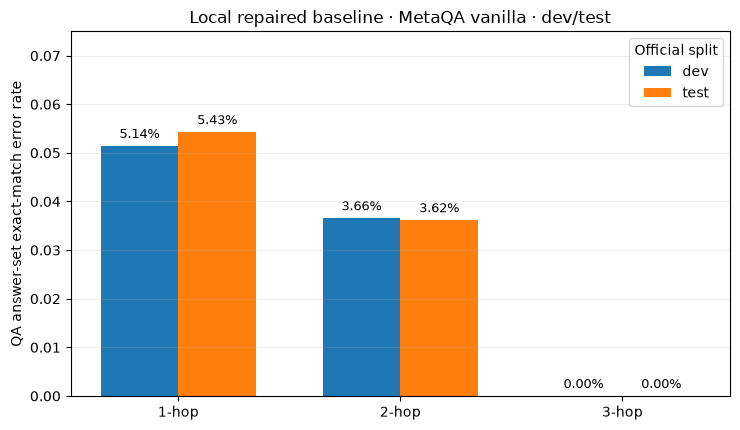

In [14]:
# Error rate begins at zero; this avoids magnifying small accuracy gaps.
from matplotlib import pyplot as plt

positions = list(range(len(HOPS)))
width = 0.35
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for offset, split, color in ((-width / 2, "dev", "tab:blue"),
                             (width / 2, "test", "tab:orange")):
    error_rates = [1 - evaluation[split][hop]["qa_exact_match"] for hop in HOPS]
    bars = ax.bar([x + offset for x in positions], error_rates,
                  width=width, label=split, color=color)
    for bar, rate in zip(bars, error_rates):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
                f"{rate:.2%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(positions, [f"{hop}-hop" for hop in HOPS])
ax.set_ylim(0, 0.075)
ax.set_ylabel("QA answer-set exact-match error rate")
ax.set_title("Local repaired baseline · MetaQA vanilla · dev/test")
ax.legend(title="Official split")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Discussion and bounded error inspection

Question-type accuracy reaches 100% on these templated vanilla dev/test questions, yet QA exact-set match is lower for 1- and 2-hop questions. The following examples inspect **actual failed test rows**. A title shared by different movies can cause a graph traversal to return extra cast members. A two-hop path can include the starting person in its answer set when that person also has the target relation. These mechanisms require explicit entity disambiguation and path/self handling if the model is improved. The 3-hop subset has zero observed errors in this run; that does not prove general reasoning beyond this dataset and graph.

The cross-split question-text overlap remains a data diagnostic, not a confirmed leak. Use dev for future design decisions and keep test for final evaluation.

In [15]:
# Two bounded test failures, selected from this run rather than invented.
for hop, cue in ((1, "School for Scoundrels"), (2, "Bob Peterson")):
    candidates = evaluation["test"][hop]["failure_examples"]
    example = next(item for item in candidates if cue in item["question"])
    print(f"\n{hop}-hop test: {example['question']}")
    print("Question type:", example["true_type"], "→", example["predicted_type"])
    print("Gold answers (up to five):", example["true_answers"])
    print("Predicted answers (up to five):", example["predicted_answers"])

# The same title points to multiple casts in the movie KB; this is an
# observable name-collision mechanism, not a judgement about the gold data.
target_title = "School for Scoundrels"
cast = set()
with kb_path.open(encoding="utf-8-sig") as source:
    for raw in source:
        subject, relation, obj = raw.rstrip("\r\n").split("|")
        if subject == target_title and relation == "starred_actors":
            cast.add(obj)
print("\nKB actors for the exact title:", target_title, sorted(cast))


1-hop test: the movie [School for Scoundrels] starred who
Question type: movie_to_actor → movie_to_actor
Gold answers (up to five): ['Billy Bob Thornton', 'Jon Heder']
Predicted answers (up to five): ['Billy Bob Thornton', 'Ian Carmichael', 'Jon Heder']

2-hop test: who are the actors in the films written by [Bob Peterson]
Question type: writer_to_movie_to_actor → writer_to_movie_to_actor
Gold answers (up to five): ['Edward Asner', 'Jordan Nagai']
Predicted answers (up to five): ['Bob Peterson', 'Edward Asner', 'Jordan Nagai']

KB actors for the exact title: School for Scoundrels ['Billy Bob Thornton', 'Ian Carmichael', 'Jon Heder']


## 7. References and contribution record

- [Official MetaQA dataset](https://github.com/yuyuz/MetaQA), source `LICENSE.txt` and `SOURCE-MANIFEST.md` beside the local download.
- [Group baseline repository](https://github.com/ltangg2/comp9444), `main` at `0f5a3fbf745937864b007bd17f95fa6e68e659b9` for this review. Cite any upstream model or code sources separately after provenance review.
- Archer: vanilla data inventory, validation, EDA and this integration scaffold. Christine: baseline code per group handoff, pending group confirmation. All group members should confirm their final contributions.

**Submission check:** one aggregate notebook only. The group should review this local-repair experiment, pin a shared code revision and reproduce its outputs before submission; it must not be presented as a run of the unchanged online baseline.